In [7]:
'''
Exploratory Data Analysis 2 SWI:  Focus on SC

To follow: Cl, CL + SC, All 

By Anita T

October 13 2023
'''

'\nExploratory Data Analysis 2 SWI \n\n- SC, Cl, CL + SC\n\nBy Anita T\n\nOctober 13 2023\n'

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
import seaborn as sns
from scipy import stats
from scipy.stats import norm

In [9]:
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number','LONGITUDE','LATITUTE']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'
    
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
#one_hot_df = pd.get_dummies(Datat['Aquifer Group'], prefix='Aquifer') #Uncomment both for regression, etc
#Datat = pd.concat([Datat, one_hot_df], axis=1)
Datat = Datat.dropna()
Datawithtime = Datat.copy()
DropDF2 = ['Aquifer Subtype', 'DATE', 'OBSWELL', 'year_month', 'Precip_Climatology',
       'Tn_Climatology', 'Tx_Climatology',]
Datat = Datat.drop(DropDF2, axis=1, errors='ignore')

In [10]:
'''
pH_values = Datat['pH'].values
median_pH = np.median(pH_values)
mad_pH = np.median(np.abs(pH_values - median_pH))

print("Unique pH values:", np.unique(pH_values))
print("Median Absolute Deviation of pH:", mad_pH)

'''

'\npH_values = Datat[\'pH\'].values\nmedian_pH = np.median(pH_values)\nmad_pH = np.median(np.abs(pH_values - median_pH))\n\nprint("Unique pH values:", np.unique(pH_values))\nprint("Median Absolute Deviation of pH:", mad_pH)\n\n'

In [11]:
'''
SWIsc Analysis 
'''
df_SWIsctime =Datawithtime[Datawithtime['Specific Conductance'] > 1000]
df_SWIsc = Datat[Datat['Specific Conductance'] > 1000]
df_SWIsc.shape

(98, 24)

In [12]:
filtered_dfAs = df_SWIsc[(df_SWIsc['As-T'] >= 0.001)]
filtered_dfAs.shape

(69, 24)

In [13]:
filtered_dfMn = df_SWIsc[(df_SWIsc['Mn-T'] >= 0.12)]
filtered_dfMn.shape

(38, 24)

In [14]:
filtered_dfPb = df_SWIsc[(df_SWIsc['Pb-T'] >= 0.005)]
filtered_dfPb.shape

(22, 24)

In [15]:
filtered_dfU = df_SWIsc[(df_SWIsc['U--T'] >= 0.02)]
filtered_dfU.shape

(0, 24)

In [16]:
filtered_dSC = df_SWIsc[(df_SWIsc['Specific Conductance'] >= 1000)]
filtered_dSC.shape

(98, 24)

In [17]:
filtered_dTDS = df_SWIsc[(df_SWIsc['Residue Filterable 1.0u'] >= 750)]
filtered_dTDS.shape

(70, 24)

In [18]:
filtered_dC = df_SWIsc[(df_SWIsc['Chlrid:D'] >= 150)]
filtered_dC.shape

(39, 24)

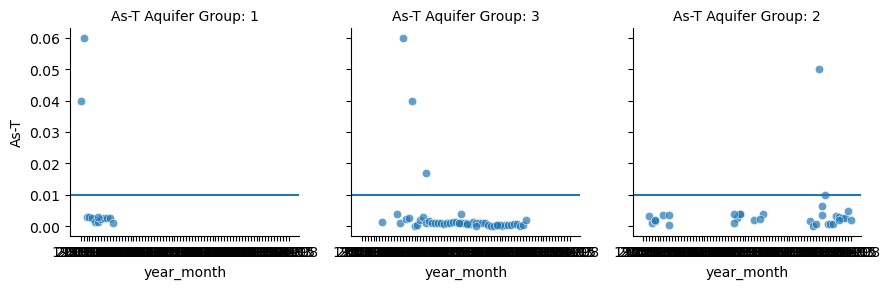

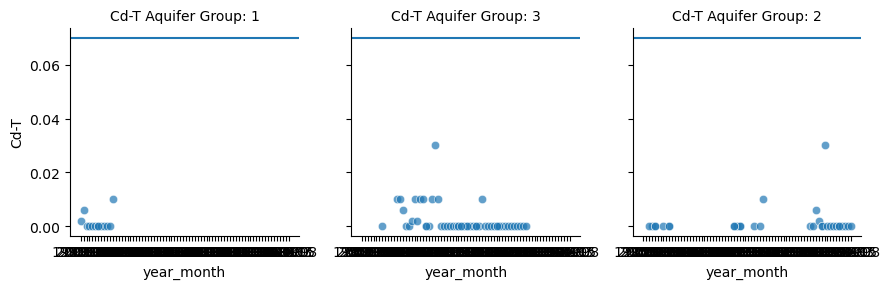

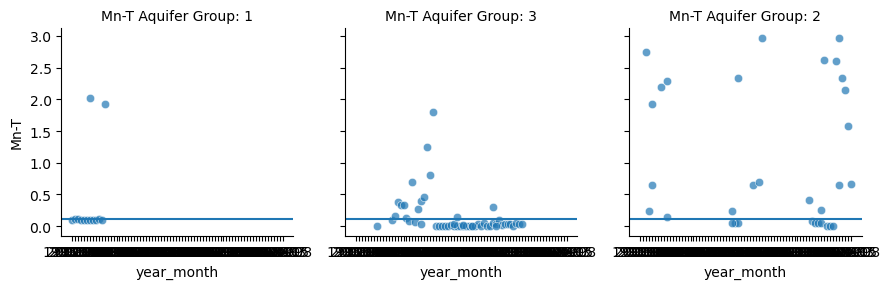

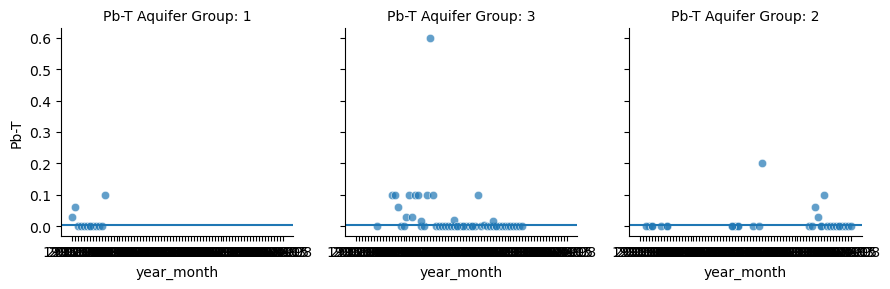

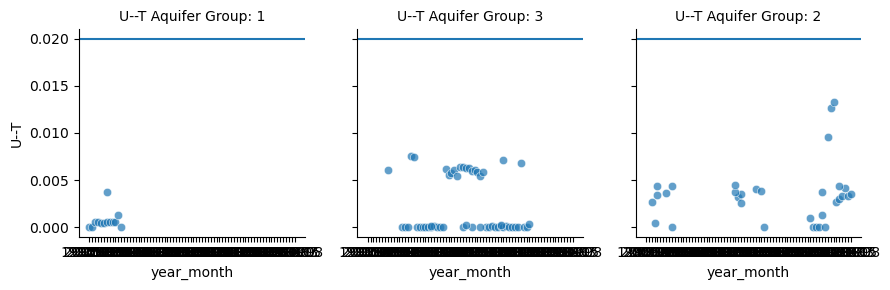

<Figure size 1000x800 with 0 Axes>

In [19]:
Total_Metals = df_SWIsctime[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group', 'year_month']]

# Assuming Total_Metals DataFrame already exists
As = sns.FacetGrid(Total_Metals, col="Aquifer Group")
As.map(sns.scatterplot, "year_month", 'As-T', alpha=.7)
As.map(lambda x, **kwargs: plt.axhline(y=0.01, **kwargs), "year_month")
As.set_titles("As-T Aquifer Group: {col_name}")  # Setting title for each subplot

Cd = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Cd.map(sns.scatterplot, "year_month", 'Cd-T', alpha=.7)
Cd.map(lambda x, **kwargs: plt.axhline(y=0.07, **kwargs), "year_month")
Cd.set_titles("Cd-T Aquifer Group: {col_name}")  # Setting title for each subplot

Mn = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Mn.map(sns.scatterplot, "year_month", 'Mn-T', alpha=.7)
Mn.map(lambda x, **kwargs: plt.axhline(y=0.12, **kwargs), "year_month")
Mn.set_titles("Mn-T Aquifer Group: {col_name}")  # Setting title for each subplot

Pb = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Pb.map(sns.scatterplot, "year_month", 'Pb-T', alpha=.7)
Pb.map(lambda x, **kwargs: plt.axhline(y=0.005, **kwargs), "year_month")
Pb.set_titles("Pb-T Aquifer Group: {col_name}")  # Setting title for each subplot

UT = sns.FacetGrid(Total_Metals, col="Aquifer Group")
UT.map(sns.scatterplot, "year_month", 'U--T', alpha=.7)
UT.map(lambda x, **kwargs: plt.axhline(y=0.02, **kwargs), "year_month")
UT.set_titles("U--T Aquifer Group: {col_name}")  # Setting title for each subplot

#plt.suptitle("Well Water Samples with As, Mn, Pb and U Concentrations over Canadian Drinking Water Standards", fontsize=12, y=1.02)
plt.tight_layout()  # This line is to prevent overlapping of the title and the top plot
plt.show()
plt.savefig('Figures/metalsoverCADdrinkingwaterSWIsc.png')

Datat.columns


#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols = ['pH']
cleaned_dataset_array = replace_outliers_with_iqr(Datat[numeric_cols], 1.5)


In [ ]:
'''
Handling Outliers

Notes:  
To prevent more outlier removal, use MAD score.  ID df_SWIsc style.  Will not to Mahalanobis method due to complexity

Decided to use threshold score instead.  MAD scores takes away from metals being past the drinking water standard and SWI values

Source:
https://stats.stackexchange.com/questions/591853/interquartile-range-finding-more-than-10-times-outliers-than-zscore#:~:text=Yes%20%2D%20using%20the%20IQR%20method,will%20find%20lots%20of%20outliers.
https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/#:~:text=The%20IQR%20can%20be%20calculated,can%20be%20considered%20an%20outlier.
https://www.analyticsvidhya.com/blog/2021/05/detecting-and-treating-outliers-treating-the-odd-one-out/
'''

def replace_outliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = upper_threshold
    return cleaned_dataset

#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols1 = ['pH', 'Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP']
cleaned_dataset_array1 = replace_outliers_with_iqr(df_SWIsc[numeric_cols1], 1.5)
df_SWIsc[numeric_cols1] = cleaned_dataset_array1


def replace_outliers_with_threshold(dataset, threshold_multiplier=3):
    """
    Replace outliers in a dataset with the threshold value based on the Median Absolute Deviation (MAD).

    Parameters:
    - dataset: DataFrame containing the dataset.
    - threshold_multiplier: Multiple of the MAD to be used as the threshold (default: 3).

    Returns:
    - cleaned_dataset: DataFrame with outliers replaced by the threshold.
    """
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        col_values = cleaned_dataset[col].values
        median = np.median(col_values)
        mad = np.median(np.abs(col_values - median))
        lower_threshold = median - threshold_multiplier * mad
        upper_threshold = median + threshold_multiplier * mad
        high_outliers = (col_values - median) > upper_threshold
        cleaned_dataset.loc[high_outliers, col] = upper_threshold
        # Update col_values after replacing high outliers
        col_values = cleaned_dataset[col].values
        low_outliers = (col_values - median) < lower_threshold
        cleaned_dataset.loc[low_outliers, col] = lower_threshold
    return cleaned_dataset
'''
# Assume df_SWIsc is your DataFrame
numeric_cols = [ 'FD', 'HW', 'MT']

# Call your function on just the numeric columns
cleaned_dataset_array = replace_outliers_with_threshold(df_SWIsc[numeric_cols], threshold_multiplier=3)

# Convert the numpy array back to a DataFrame
cleaned_dataset = pd.DataFrame(cleaned_dataset_array, columns=numeric_cols, index=df_SWIsc.index)

df_SWIsc[numeric_cols] = cleaned_dataset
'''
df_SWIscpastremoval1 = df_SWIsc.copy() #This is incase I screw up. Can be commented out.

#cleaned_dataset.to_csv('cleaned_dataset.csv')

In [21]:
Datat.head()

,Alkalinity Total 4.5,As-T,Ca-T,Cd-T,Chlrid:D,Fe-T,Mn-T,N.Kjel:T,P--T,Pb-T,...,Hardness Total (T),K--T,U--T,PRECIPITATION,MIN_TEMP,MAX_TEMP,FD,HW,MT,Aquifer Group
0,272.0,0.04000,109.0,0.002000,125.0,3.01,0.0970,0.240,0.092,0.03000,...,393.20102,0.025,0.000001,60.4,8.693548,22.290323,22.5657,-4.062877,-0.965552,1
1,336.0,0.06000,113.0,0.006000,112.0,4.49,0.1090,0.005,0.106,0.06000,...,414.34880,6.600,0.000001,44.6,10.596774,26.032258,-4.9586,-0.458242,0.469774,1
2,371.0,0.00290,141.0,0.000010,176.0,5.16,0.1100,0.200,0.100,0.00029,...,501.14860,8.000,0.000540,53.7,6.096774,21.709677,8.5384,2.203777,1.175854,1
3,365.0,0.00300,132.0,0.000010,159.0,3.59,0.0969,0.160,0.099,0.00003,...,470.85140,8.000,0.000581,109.0,3.161290,12.306452,67.0441,0.253052,2.162414,1
4,350.0,0.00249,107.0,0.000005,100.0,1.78,0.0955,0.140,0.064,0.00002,...,381.00000,7.440,0.000468,44.5,10.693548,27.903226,6.6657,1.550026,1.034448,1


In [22]:
from sklearn.preprocessing import PowerTransformer

# Create a PowerTransformer object
pt = PowerTransformer(method='yeo-johnson')

# Define the column names you want to transform
cols_to_transform = ['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP']
# Apply the transformation to the specified columns
df_SWIsc[cols_to_transform] = pt.fit_transform(df_SWIsc[cols_to_transform])

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_22532\1627318250.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SWIsc[cols_to_transform] = pt.fit_transform(df_SWIsc[cols_to_transform])


In [23]:
df_SWIsc.shape

(98, 24)

In [24]:
#df_SWIsc.to_csv('df_SWIsc.csv')

In [25]:
df_SWIsc.shape

(98, 24)

In [26]:
df_SWIsc.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group'],
      dtype='object')

In [27]:
# import pandas and numpy if they're not already imported
import pandas as pd
import numpy as np

# assuming `df` is your DataFrame
selected_columns = df_SWIsc.iloc[:, :23]  # select the first 26 columns
group_column = df_SWIsc.iloc[:, 23]  # select the 27th column

# group the selected columns by the values in the group column
grouped = selected_columns.groupby(group_column)

# get the unique group names
groups = df_SWIsc.iloc[:, 23].unique()

# calculate summary statistics and percentiles for each group
all_summaries3 = []  # list to hold summary dataframes for each group
for group in groups:
    # select data for this group
    this_group = grouped.get_group(group)

    # calculate summary statistics
    summary = this_group.agg(['mean', 'var', 'std', 'min', 'max', 'skew', 'median', pd.DataFrame.kurt])

    # calculate percentiles and add them to the summary
    for q in [0.1, 0.5, 0.9]:
        summary.loc[f'{q*100}% percentile'] = this_group.quantile(q)

    # calculate coefficient of variation and add it to the summary
    summary.loc['cv'] = this_group.std() / this_group.mean()

    # add the group name as the top level of the index
    summary.index = pd.MultiIndex.from_product([[group], summary.index])

    # add this group's summary to the list
    all_summaries3.append(summary)

# concatenate all the group summaries into one DataFrame
summary_df3 = pd.concat(all_summaries3)

# save to CSVWhich is the best given datasets have range between 0.000001-0.027475 in one column and 3580.000000-0.025000 in another?


summary_df3.to_csv('Stats/statssummarySWIsc.csv')

# check the DataFrame
print(summary_df3)

                    Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
1 mean                         -0.169358  0.657945  0.891572 -0.230994   
  var                           0.036112  0.486947  0.158243  1.209804   
  std                           0.190033  0.697816  0.397797  1.099911   
  min                          -0.609105 -0.517998  0.218919 -0.876170   
  max                           0.125130  1.791045  1.955612  1.689802   
  skew                         -0.796539 -0.074113  1.344418  1.416861   
  median                       -0.150830  0.753202  0.935778 -0.876170   
  kurt                          1.158446 -0.045515  4.352338  0.043930   
  10.0% percentile             -0.319444 -0.268713  0.622207 -0.876170   
  50.0% percentile             -0.150830  0.753202  0.935778 -0.876170   
  90.0% percentile              0.004386  1.614461  1.097781  1.689802   
  cv                           -1.122077  1.060599  0.446175 -4.761644   
3 mean                         -0.0730

In [28]:
correlation_matSWIsc = df_SWIsc.corr()
correlation_matSWIsc.to_csv('Stats/correlation_matafterSWIsc.csv')
print(correlation_matSWIsc)


                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.095004 -0.026313 -0.231438   
As-T                                 0.095004  1.000000  0.310411  0.214049   
Ca-T                                -0.026313  0.310411  1.000000  0.082390   
Cd-T                                -0.231438  0.214049  0.082390  1.000000   
Chlrid:D                            -0.291186 -0.381985 -0.372177  0.171694   
Fe-T                                -0.185747  0.368926  0.086423  0.504318   
Mn-T                                -0.275422  0.430330  0.270820  0.149935   
N.Kjel:T                            -0.119241 -0.375921 -0.068726 -0.076692   
P--T                                 0.197273  0.148551  0.057218 -0.049360   
Pb-T                                -0.278054  0.189748  0.005408  0.887296   
Residue Filterable 1.0u             -0.332479 -0.124554  0.042630  0.419343   
Specific Conductance                -0.192335 -0.235

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_22532\3579596094.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matSWIsc = df_SWIsc.corr()


In [29]:
correlation_tauSWIsc = df_SWIsc.corr(method='kendall')
print(correlation_tauSWIsc)
correlation_tauSWIsc.to_csv('Stats/correlation_tauSWIsc.csv')

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_22532\3630452485.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_tauSWIsc = df_SWIsc.corr(method='kendall')


                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.078010 -0.027863 -0.134525   
As-T                                 0.078010  1.000000  0.217184  0.076241   
Ca-T                                -0.027863  0.217184  1.000000 -0.029574   
Cd-T                                -0.134525  0.076241 -0.029574  1.000000   
Chlrid:D                            -0.220033 -0.272455 -0.235137  0.140130   
Fe-T                                -0.043941  0.268400  0.083078  0.303723   
Mn-T                                -0.203901  0.305136  0.113909  0.116712   
N.Kjel:T                            -0.052516 -0.260665 -0.002554  0.024824   
P--T                                 0.095815  0.144833  0.049438  0.042075   
Pb-T                                -0.179670  0.119738 -0.084451  0.607385   
Residue Filterable 1.0u             -0.115869 -0.124376 -0.031958  0.342029   
Specific Conductance                -0.075977 -0.196

In [30]:
correlation_rhoSWIsc = df_SWIsc.corr(method='spearman')
correlation_rhoSWIsc.to_csv('Stats/correlation_rhoSWIsc.csv')
print(correlation_rhoSWIsc)

                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.113778 -0.007075 -0.185971   
As-T                                 0.113778  1.000000  0.314202  0.125814   
Ca-T                                -0.007075  0.314202  1.000000 -0.040887   
Cd-T                                -0.185971  0.125814 -0.040887  1.000000   
Chlrid:D                            -0.328252 -0.381683 -0.366744  0.195509   
Fe-T                                -0.099953  0.353864  0.091663  0.417776   
Mn-T                                -0.325345  0.474770  0.160140  0.146491   
N.Kjel:T                            -0.082443 -0.361848 -0.008755  0.025154   
P--T                                 0.137118  0.198360  0.061124  0.055234   
Pb-T                                -0.255060  0.162844 -0.106102  0.763320   
Residue Filterable 1.0u             -0.209529 -0.172295 -0.047751  0.440688   
Specific Conductance                -0.170755 -0.266

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_22532\68467483.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_rhoSWIsc = df_SWIsc.corr(method='spearman')


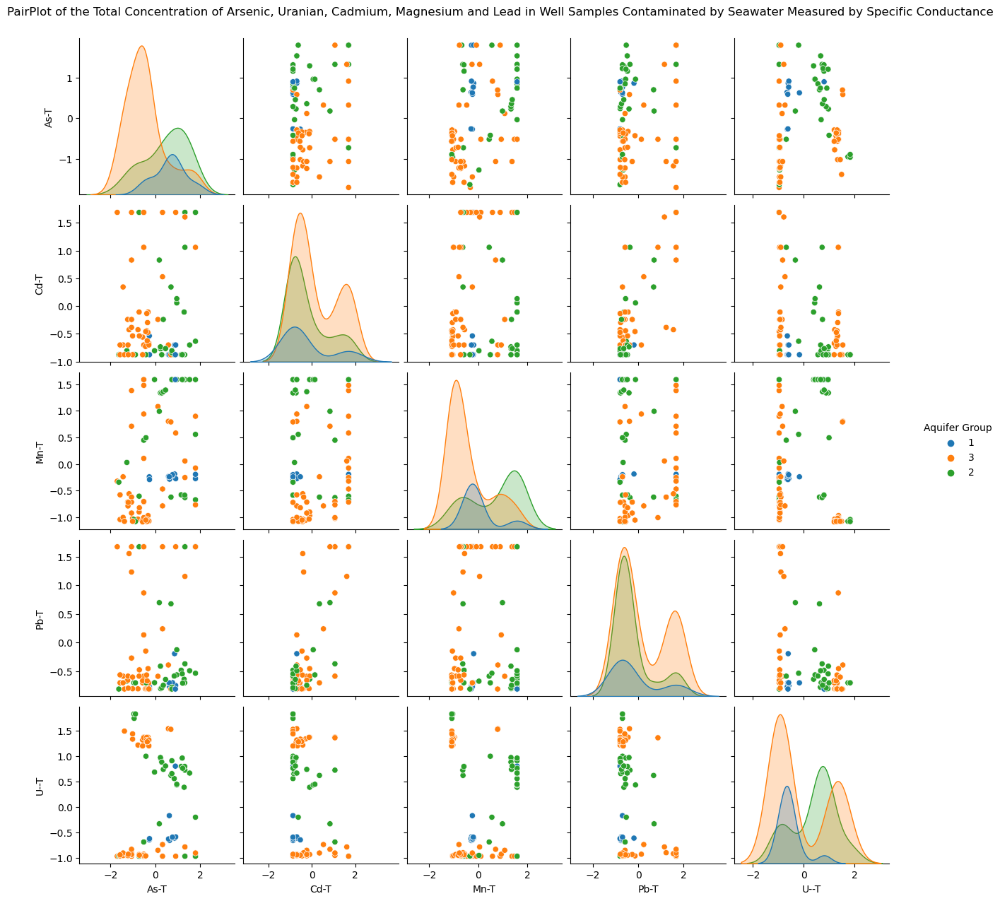

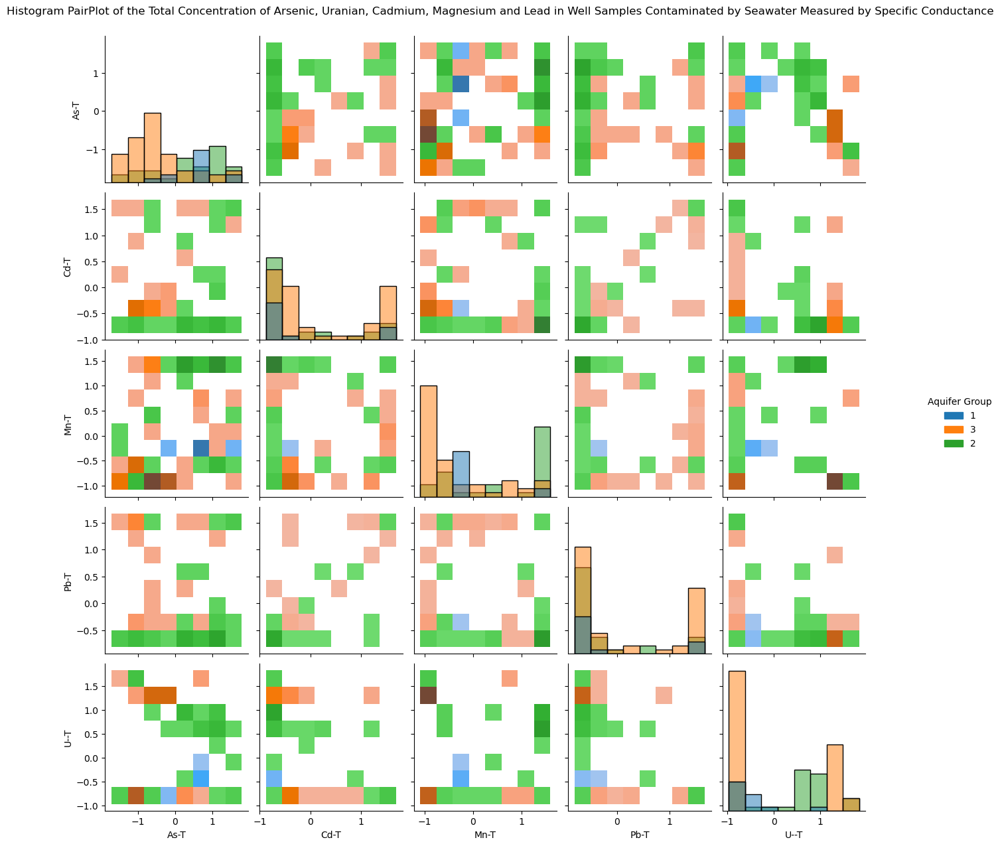

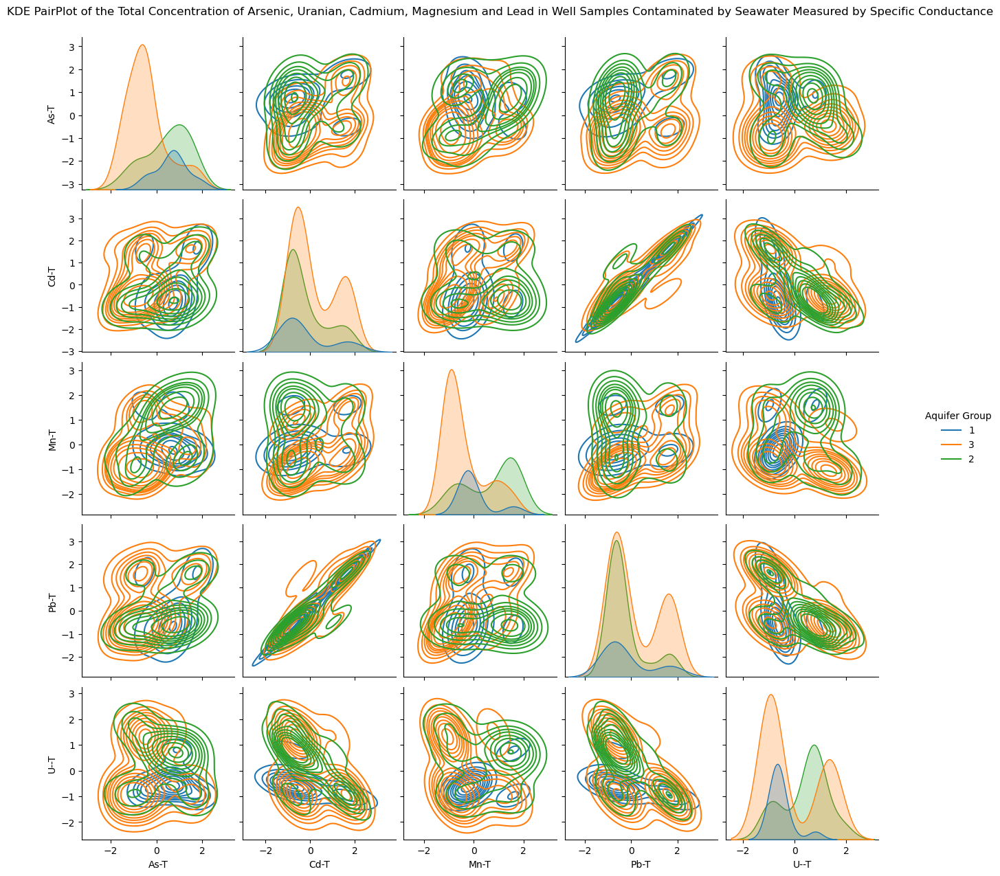

In [31]:
Metals_Total = df_SWIsc[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group']]
Metalsg = sns.pairplot(Metals_Total, hue="Aquifer Group")
Metalsg.fig.suptitle("PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/pairplotmetalsSWIsc.png') # Save the first figure

Metalsh = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="hist")
Metalsh.fig.suptitle("Histogram PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/histplotmetalsSWIsc.png') 

Metalsf = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="kde")
Metalsf.fig.suptitle("KDE PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/KDEplotmetalsSWIsc.png') 


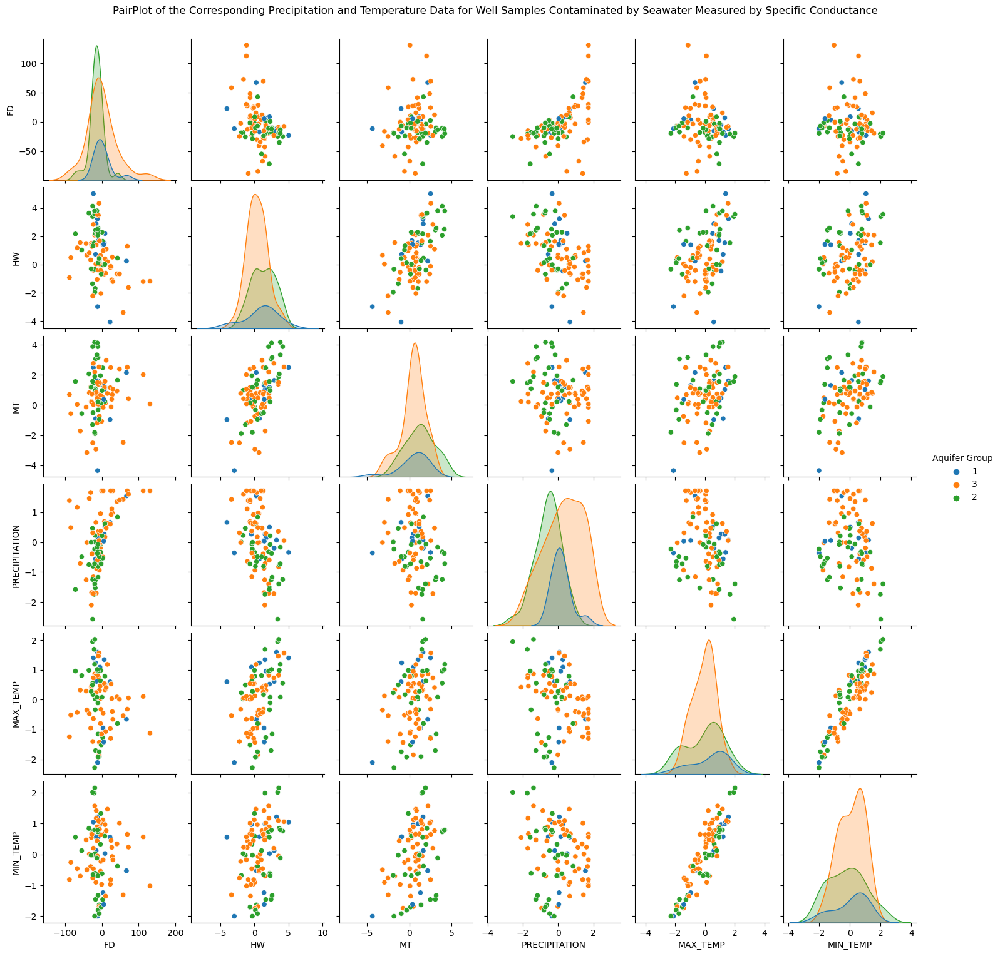

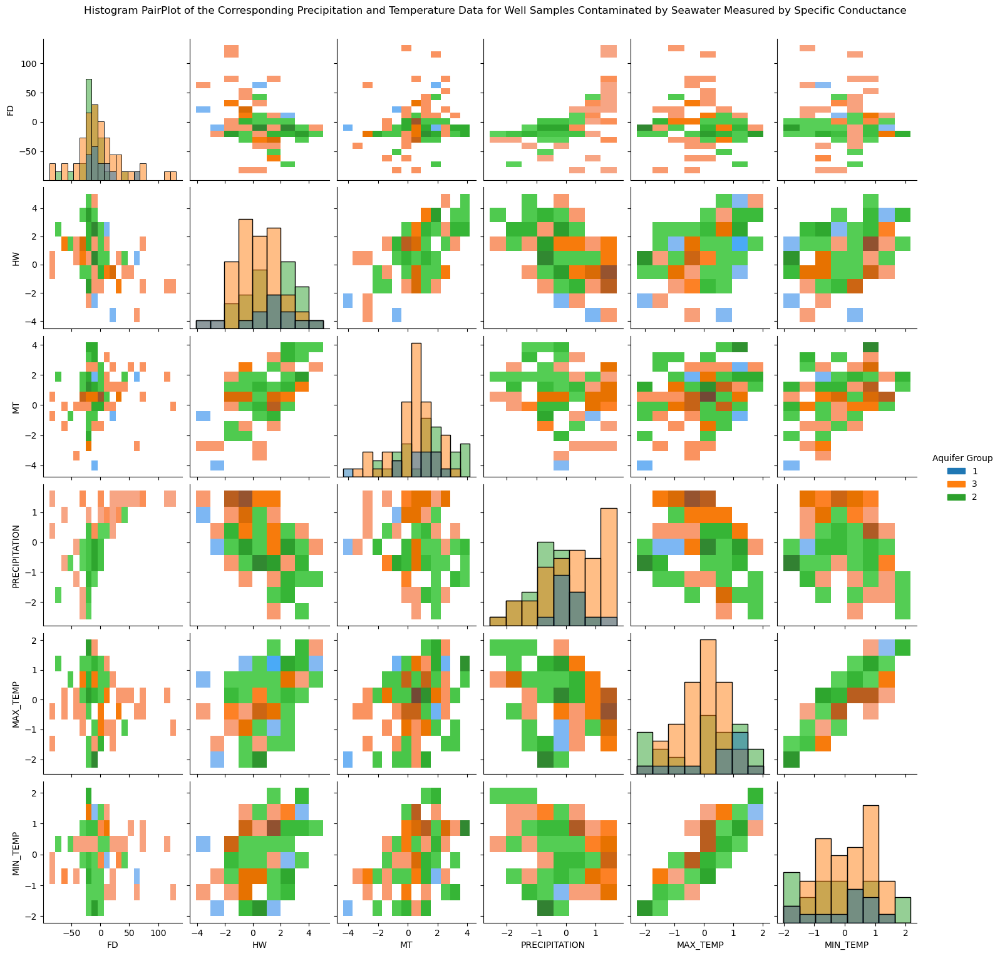

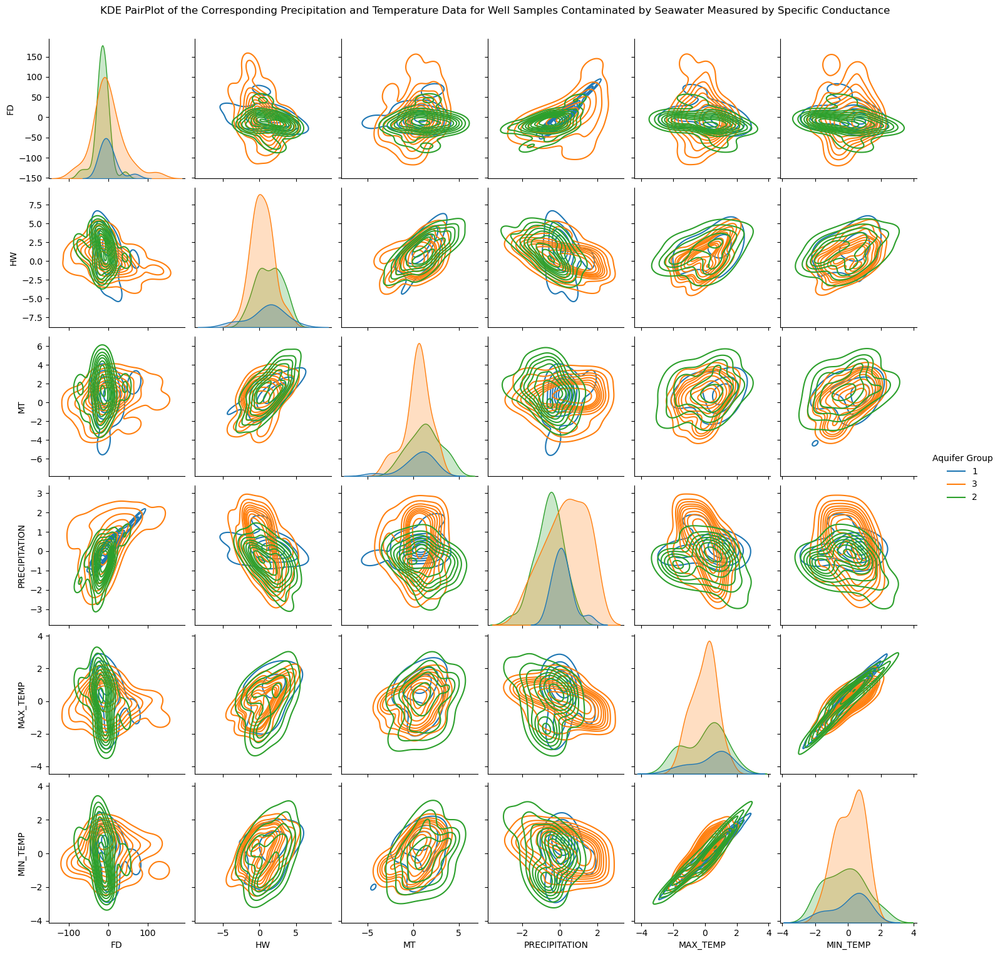

In [32]:
Precept = df_SWIsc[['FD', 'HW', 'MT', 'Aquifer Group', 'PRECIPITATION', 'MAX_TEMP', 'MIN_TEMP']]
Preceptg= sns.pairplot(Precept, hue="Aquifer Group")
Preceptg.fig.suptitle("PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/pairplotPreceptSWIsc.png') # Save the first figure

Precepth = sns.pairplot(Precept, hue="Aquifer Group", kind="hist")
Precepth.fig.suptitle("Histogram PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/histplotPreceptSWIsc.png') 

Preceptf = sns.pairplot(Precept, hue="Aquifer Group", kind="kde")
Preceptf.fig.suptitle("KDE PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/KDEplotPreceptSWIsc.png') 

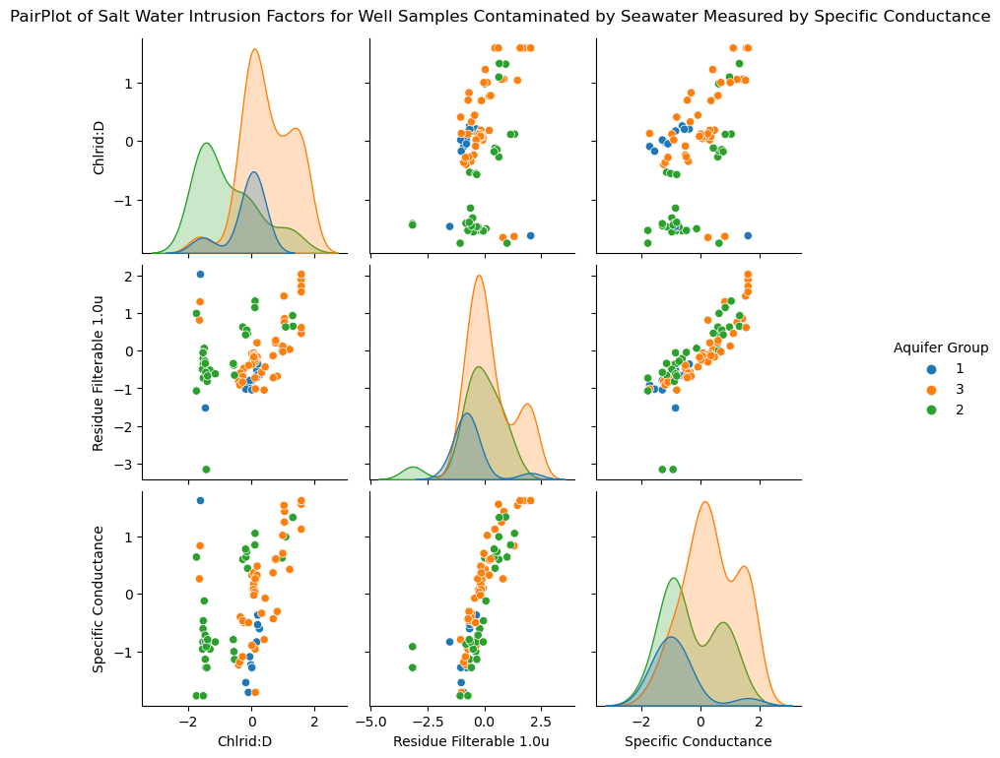

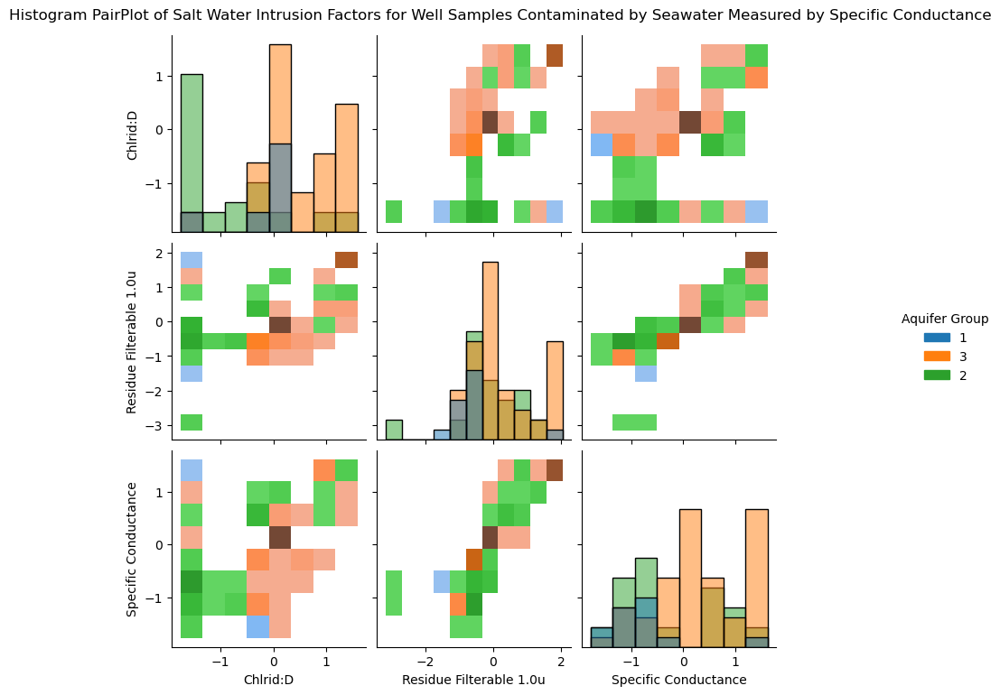

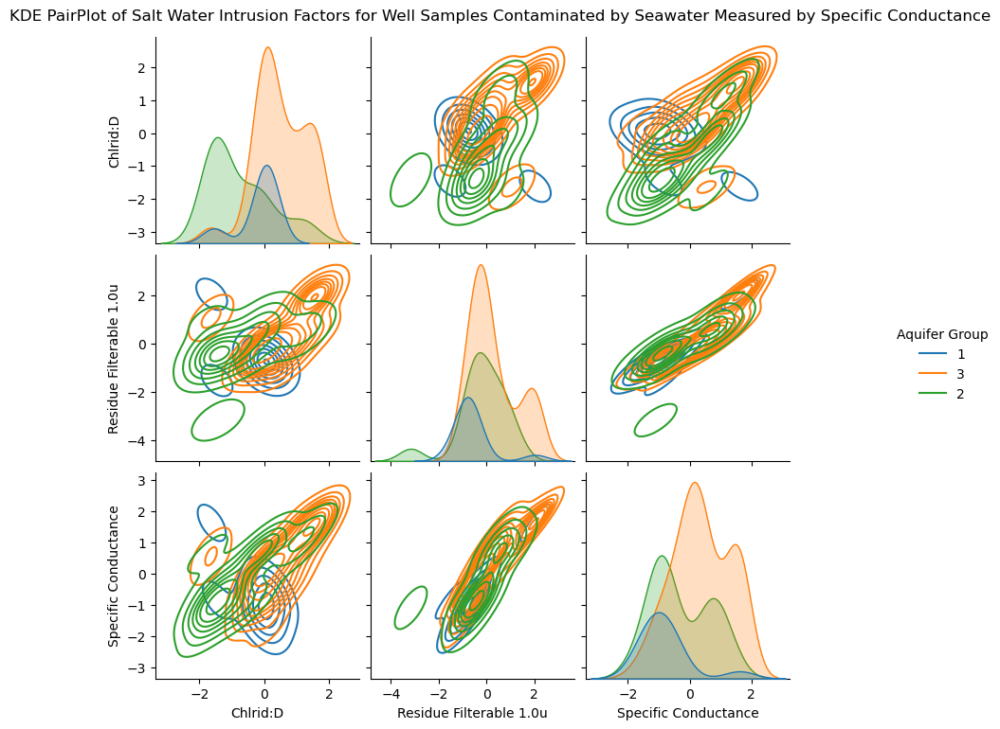

In [33]:
SWID = df_SWIsc[['Chlrid:D', 'Residue Filterable 1.0u', 'Specific Conductance', 'Aquifer Group']]
SWIDg= sns.pairplot(SWID, hue="Aquifer Group")
SWIDg.fig.suptitle("PairPlot of Salt Water Intrusion Factors for Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/pairplotSWIDSWIsc.png') # Save the first figure

SWIDh = sns.pairplot(SWID, hue="Aquifer Group", kind="hist")
SWIDh.fig.suptitle("Histogram PairPlot of Salt Water Intrusion Factors for Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/histplotSWIDSWIsc.png') 

SWIDf = sns.pairplot(SWID, hue="Aquifer Group", kind="kde")
SWIDf.fig.suptitle("KDE PairPlot of Salt Water Intrusion Factors for Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/KDEplotSWIDSWIsc.png') 

In [34]:
OthersD = df_SWIsc[['Alkalinity Total 4.5', 'Ca-T', 'Fe-T',
       'N.Kjel:T', 'P--T', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T', 'Aquifer Group']]

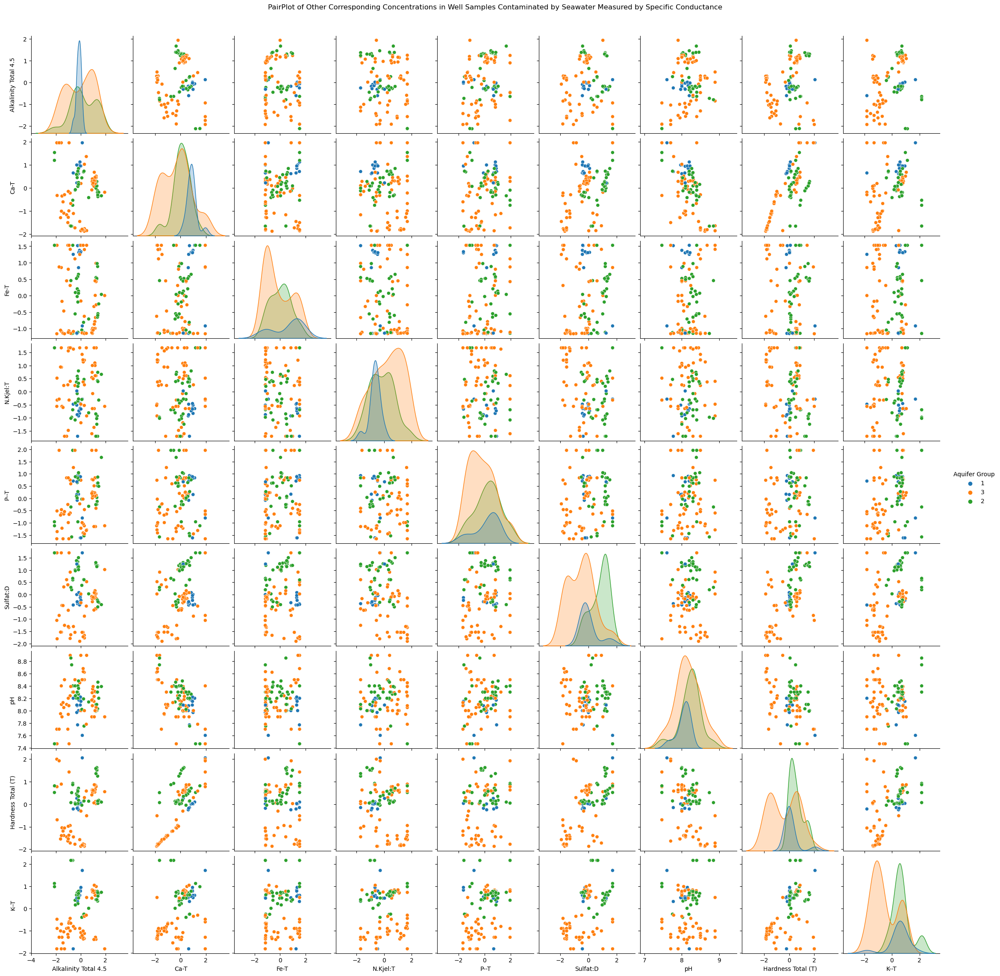

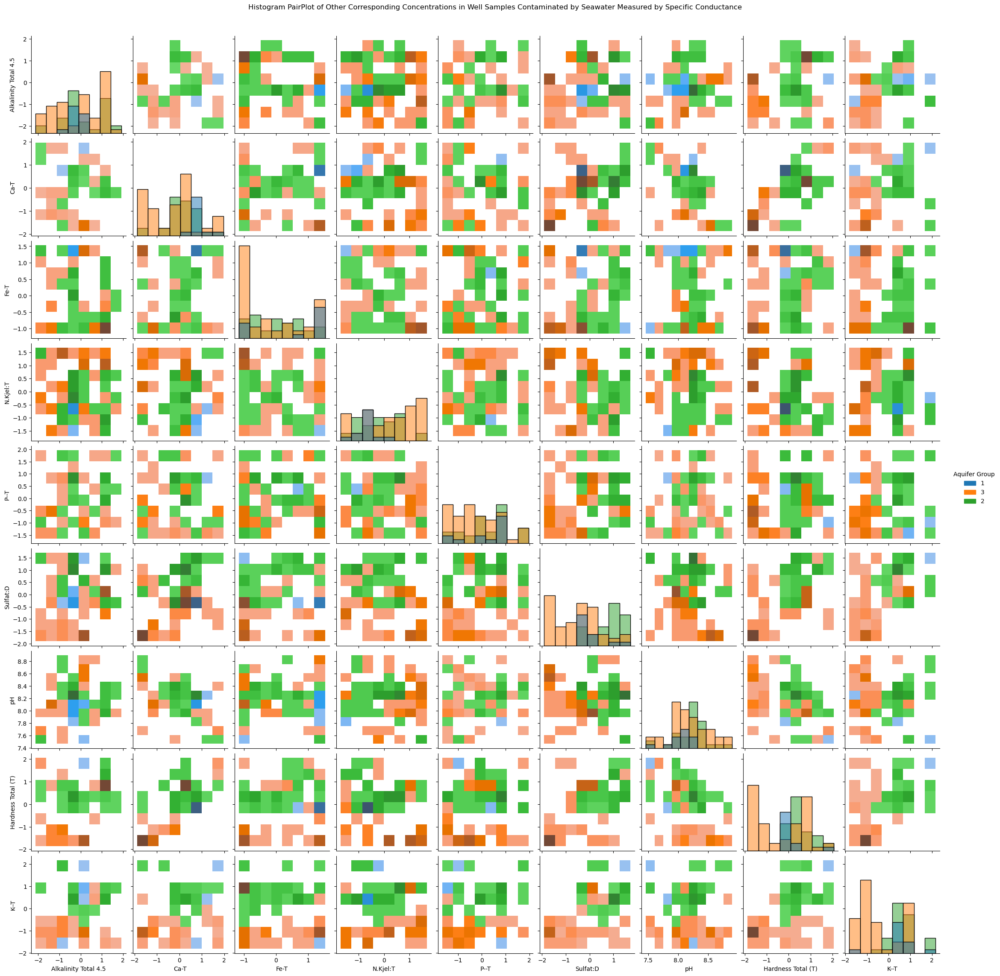

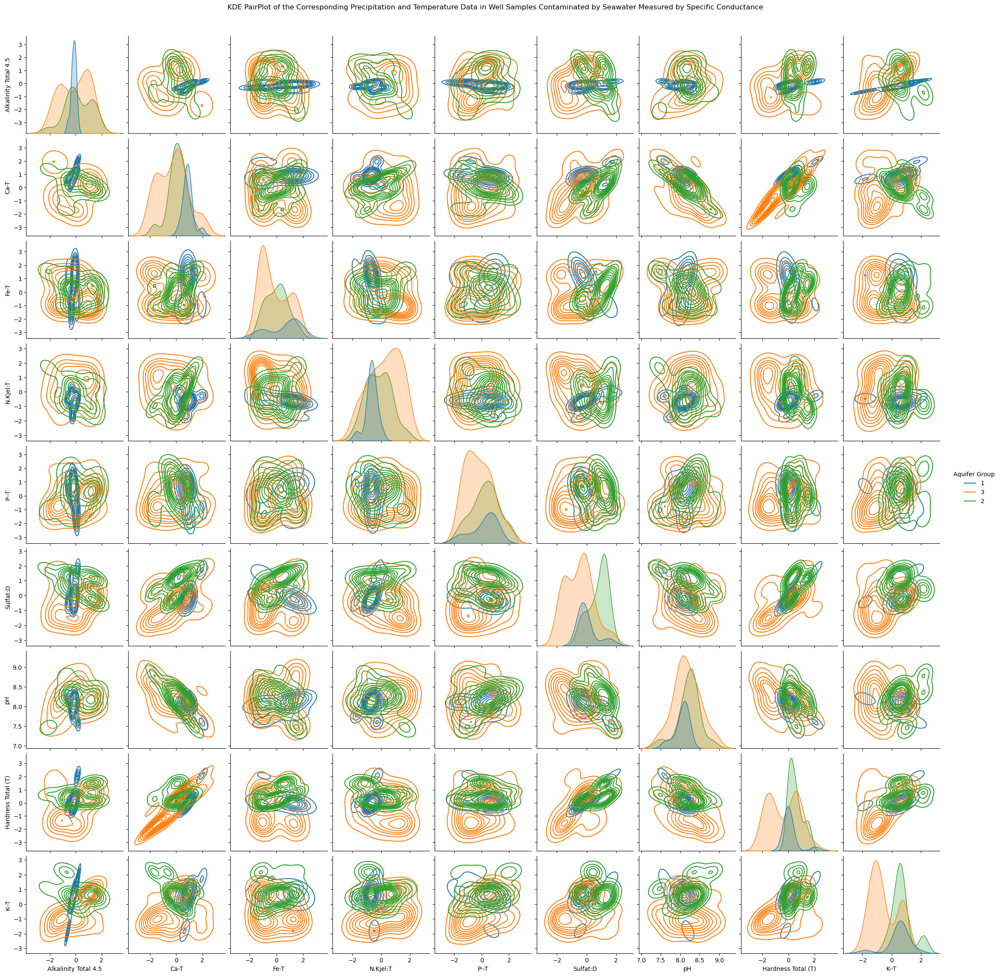

In [35]:
OthersDg= sns.pairplot(OthersD, hue="Aquifer Group")
OthersDg.fig.suptitle("PairPlot of Other Corresponding Concentrations in Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/pairplotOthersDSWIsc.png') # Save the first figure

OthersDh = sns.pairplot(OthersD, hue="Aquifer Group", kind="hist")
OthersDh.fig.suptitle("Histogram PairPlot of Other Corresponding Concentrations in Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/histplotOthersDSWIsc.png') 

Othersf = sns.pairplot(OthersD, hue="Aquifer Group", kind="kde")
Othersf.fig.suptitle("KDE PairPlot of the Corresponding Precipitation and Temperature Data in Well Samples Contaminated by Seawater Measured by Specific Conductance", y=1.02)
plt.savefig('Figures/KDEplotOthersSWIsc.png') 

In [36]:
df_SWIsc.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group'],
      dtype='object')

In [37]:
df_SWIsc.shape

(98, 24)

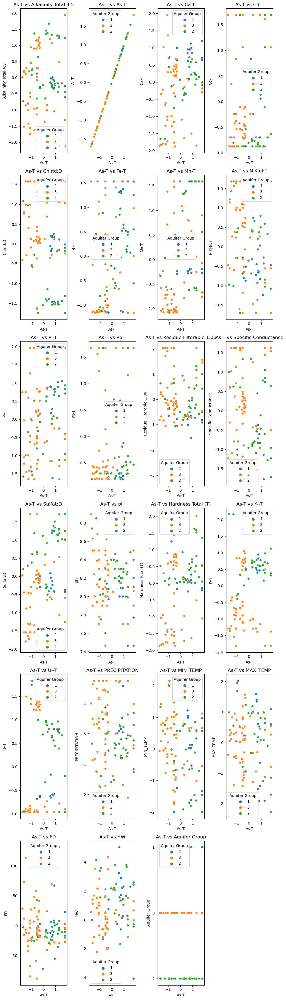

<Figure size 1000x800 with 0 Axes>

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_SWIsc is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWIsc.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='As-T', y=pmetal, data=df_SWIsc, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'As-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/ASTSWIsc.png') 

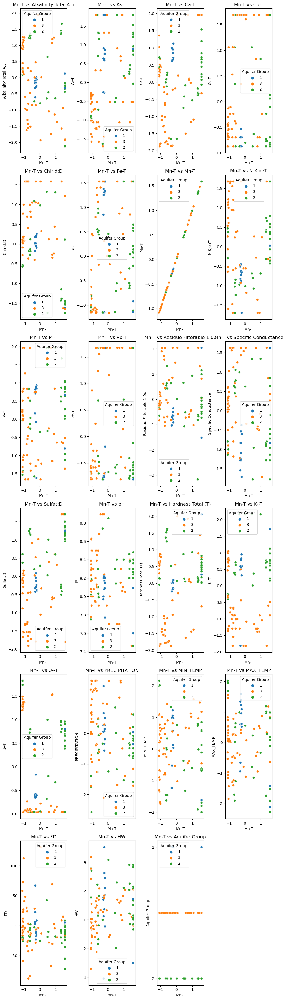

<Figure size 1000x800 with 0 Axes>

In [39]:
# Assuming df_SWIsc is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWIsc.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='Mn-T', y=pmetal, data=df_SWIsc, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'Mn-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/MnTSWIsc.png') 

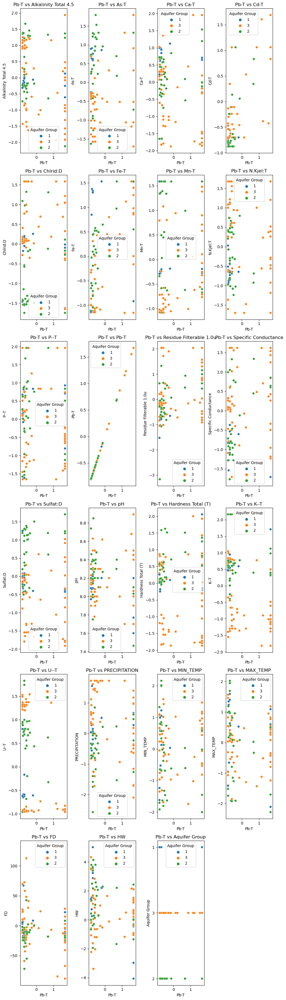

<Figure size 1000x800 with 0 Axes>

In [40]:
# Assuming df_SWIsc is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWIsc.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='Pb-T', y=pmetal, data=df_SWIsc, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'Pb-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/PbTSWIsc.png') 

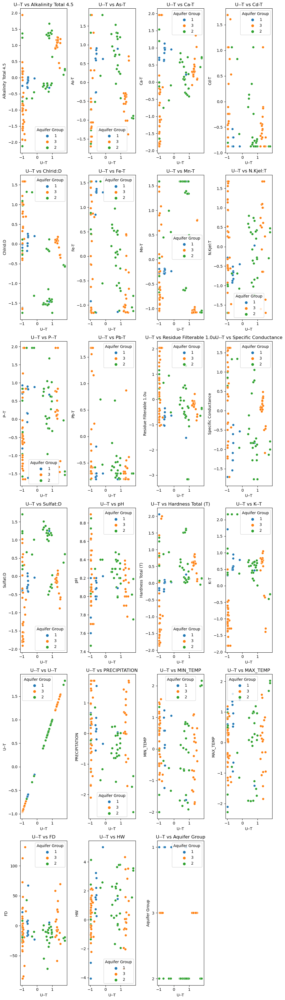

<Figure size 1000x800 with 0 Axes>

In [41]:
# Assuming df_SWIsc is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_SWIsc.columns if col != 'MT']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='U--T', y=pmetal, data=df_SWIsc, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'U--T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/UTSWIsc.png') 

In [43]:
df_SWIsctime = Datawithtime[Datat['Specific Conductance'] > 1000]
cleaned_dataset_array2 = replace_outliers_with_iqr(df_SWIsctime[numeric_cols1], 1.5)
df_SWIsctime[numeric_cols1] = cleaned_dataset_array2
#cleaned_dataset_array2a = replace_outliers_with_threshold(df_SWIsctime[numeric_cols], threshold_multiplier=3)
#cleaned_dataset2 = pd.DataFrame(cleaned_dataset_array2a, columns=numeric_cols, index=df_SWIsctime.index)
#df_SWIsctime[numeric_cols] = cleaned_dataset2

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_22532\986969179.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SWIsctime[numeric_cols1] = cleaned_dataset_array2


In [44]:
CANDMetalspre = df_SWIsctime[['OBSWELL', 'As-T', 'Mn-T', 'Pb-T', 'U--T']]
filtered_dfAs = CANDMetalspre[(CANDMetalspre['As-T'] >= 0.01)]
obs_well_valuesAs = filtered_dfAs['OBSWELL']
obs_well_valuesAs.shape

(0,)

In [45]:
filtered_dfMn = CANDMetalspre[(CANDMetalspre['Mn-T'] >= 0.12)]
obs_well_valuesMn = filtered_dfMn['OBSWELL']
obs_well_valuesMn.shape

(38,)

In [46]:
filtered_dfPb = CANDMetalspre[(CANDMetalspre['Pb-T'] >= 0.005)]
obs_well_valuesPb = filtered_dfPb['OBSWELL']
obs_well_valuesPb.shape

(0,)

In [47]:
filtered_dfU = CANDMetalspre[(CANDMetalspre['U--T'] >= 0.02)]
obs_well_valuesU = filtered_dfU['OBSWELL']
obs_well_valuesU.shape

(0,)

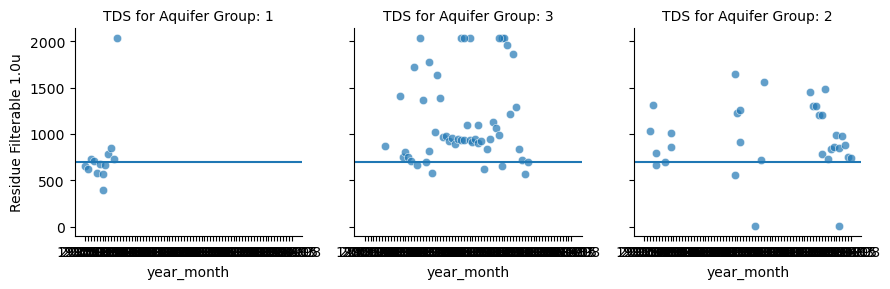

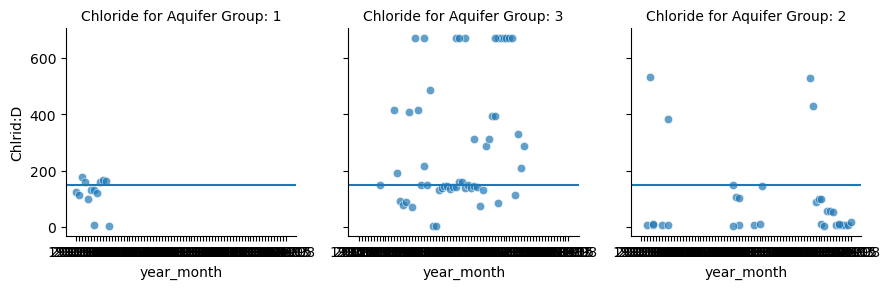

In [48]:
'''
Graphs of Saltwater intrusion
'''
SI_values = df_SWIsctime[['year_month', 'Residue Filterable 1.0u','Specific Conductance', 'Chlrid:D', 'Aquifer Group']]


TDS = sns.FacetGrid(SI_values, col="Aquifer Group")
TDS.map(sns.scatterplot, "year_month", "Residue Filterable 1.0u", alpha=.7)
TDS.map(lambda x, **kwargs: plt.axhline(y=700, **kwargs), "year_month")
TDS.set_titles("TDS for Aquifer Group: {col_name}")  # Setting title for each subplot
'''
SC = sns.FacetGrid(SI_values, col="Aquifer Group")
SC.map(sns.scatterplot, "year_month", 'Specific Conductance', alpha=.7)
SC.map(lambda x, **kwargs: plt.axhline(y=1000, **kwargs), "year_month")
SC.set_titles("Specific Conductance for Aquifer Group: {col_name}")  # Setting title for each subplot
'''
Cld = sns.FacetGrid(SI_values, col="Aquifer Group")
Cld.map(sns.scatterplot, 'year_month', 'Chlrid:D', alpha=.7)
Cld.map(lambda x, **kwargs: plt.axhline(y=150, **kwargs), "year_month")
Cld.set_titles("Chloride for Aquifer Group: {col_name}")  # Setting title for each subplot

plt.savefig('Figures/SIoverwellstimeSWIsc.png')

In [49]:
SWInow = df_SWIsctime[['OBSWELL', 'Residue Filterable 1.0u','Specific Conductance', 'Chlrid:D',]]

filtered_dTDS = SWInow[(SWInow['Residue Filterable 1.0u'] >= 750)]
obs_well_valuesTDS = filtered_dTDS['OBSWELL']
obs_well_valuesTDS.shape

(70,)

In [50]:
filtered_dSC = SWInow[(SWInow['Specific Conductance'] >= 1000)]
obs_well_valuesSC = filtered_dSC['OBSWELL']
obs_well_valuesSC.shape

(98,)

In [51]:
filtered_dC = SWInow[(SWInow['Chlrid:D'] >= 150)]
obs_well_valuesC = filtered_dC['OBSWELL']
obs_well_valuesC.shape

(39,)

In [52]:
df_SWIsctime = Datawithtime.copy()  # create a copy of Datawithtime to avoid modifying the original DataFrame
df_SWIsctime['DATE'] = pd.to_datetime(df_SWIsctime['DATE'])  # convert 'DATE' column to datetime
df_SWIsctime['Year'] = df_SWIsctime['DATE'].dt.year  # extract year from 'DATE' column
'''
SWISC = df_SWIsctime.pivot_table(index="OBSWELL", columns="Year", values="Specific Conductance")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWISC, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by Specific Conductance Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapSCSWIsc.png') 
'''

'\nSWISC = df_SWIsctime.pivot_table(index="OBSWELL", columns="Year", values="Specific Conductance")\n\n# Create the heatmap\nplt.figure(figsize=(10,8))  # optionally set the figure size\nax = sns.heatmap(SWISC, annot=False, cmap=\'viridis_r\')\n# Set the size of the x and y tick labels\nax.xaxis.set_tick_params(labelsize=8)\nax.yaxis.set_tick_params(labelsize=8)\nplt.title(\'Salt Water Intrusion by Specific Conductance Wells Throughtout Years\')  # add a title\nplt.show()\nplt.savefig(\'Figures/SWIheatmapSCSWIsc.png\') \n'

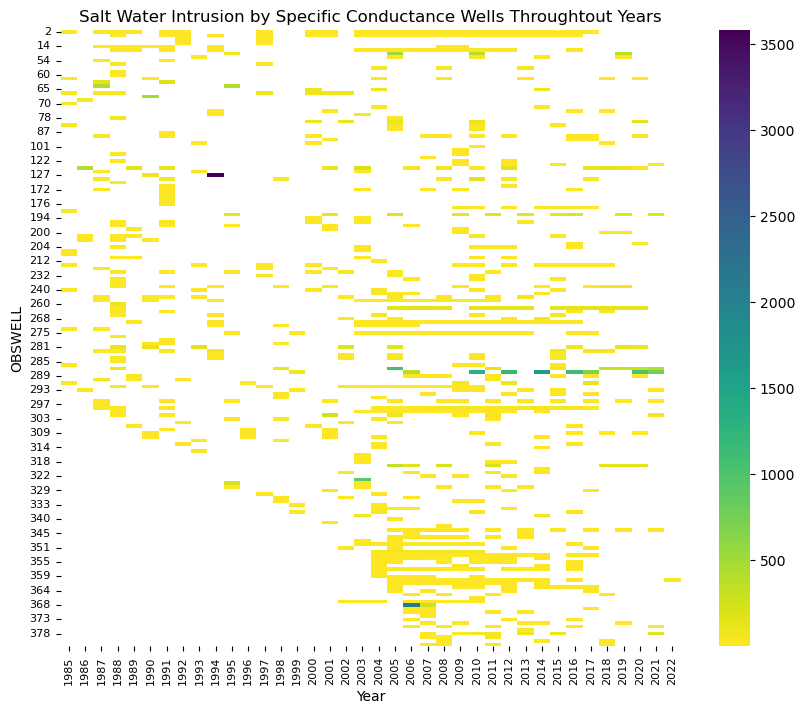

<Figure size 1000x800 with 0 Axes>

In [57]:
SWIcl = df_SWIsctime.pivot_table(index="OBSWELL", columns="Year", values="Chlrid:D")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWIcl, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by Specific Conductance Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapClSWIsc.png') 

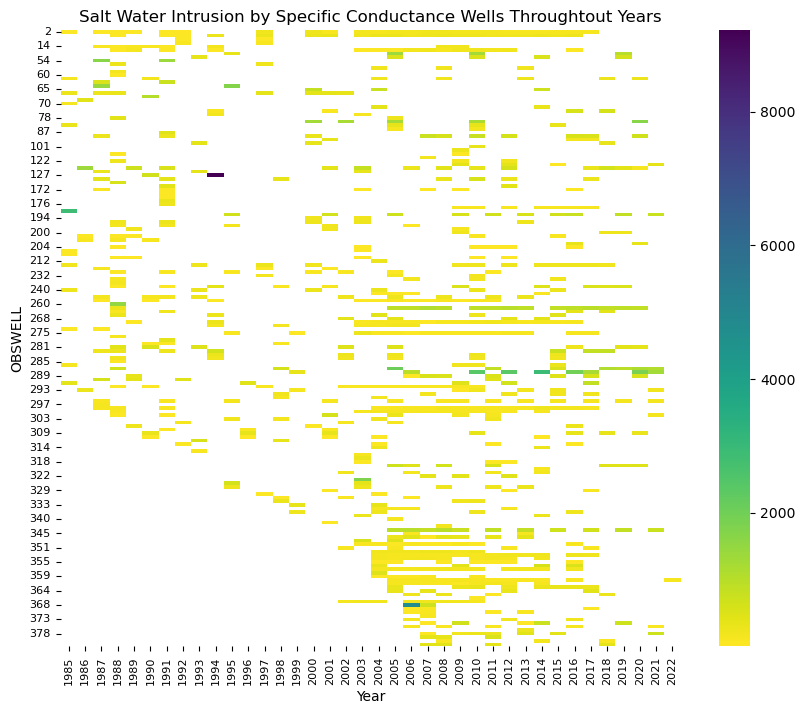

<Figure size 1000x800 with 0 Axes>

In [58]:
SWItds = df_SWIsctime.pivot_table(index="OBSWELL", columns="Year", values="Residue Filterable 1.0u")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWItds, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by Specific Conductance Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapTDSSWIsc.png')

